rumz
# Notebook for processing bubbles in Ice Cores
### Updated Sept 25
#### V. 3.1
- updated to match file processing updates: 1.3
- Used adaptive thresholding: 2.2
- updated with better bubble detection: 3.1

This notebook processes hyperspectral images of ice and extracts information in regards to the bubbles.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
# Importing Python Libraries
import warnings
import sys
import os
import matplotlib as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

In [2]:
DataID = "HSIUM-103" #insert DataID from excel file inside quotation marks

## This should be its own function ##
NumID = int(DataID.split('-')[-1])
if NumID <= 228:
    datasetPath = '/data/icecores/HSI_2024.csv'
elif 229 <= NumID < 335:
    datasetPath = '/data/icecores/HSI_2023_1.csv'
elif 335 <= NumID < 363:
    datasetPath = '/data/icecores/HSI_June2025.csv'
elif 363 <= NumID < 586:
    datasetPath = '/data/icecores/HSI_Sept2025.csv'
elif 586 <= NumID < 774:
    datasetPath = '/data/icecores/HSI_Denali2025.csv'
elif 774 <= NumID < 896:
    datasetPath = '/data/icecores/HSI_Jan2024.csv'
elif 896 <= NumID < 899:
    datasetPath = '/data/icecores/HSI_2024.csv'
else:
    raise ValueError(f"NumID {NumID} is outside supported ranges (<=228, 229–334, 335–362, 363–585, 586–750, 751–872). \n Please check DataID and try again.")
    

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "BubblesNB"

Debug = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

# bottom_depth = 162.455

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath)
# print(fwhm)

Core:  ALHIC 2302
Section:  29 Sec 33
Lighting: Top light - 50%, Bottom Light - 100%
Exposure:  10
Top Depth:  26.07
Bottom Depth:  27.03
Length =  0.9600000000000009
Dimensions:  1390, 6770, 150,850
Data Path:  July2024/ALHIC2302-29_0002_HSI_UM_Jul24
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29/2026-03-23_135520
<class 'numpy.ndarray'>


In [4]:
segment_boundaries, pixels_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, start_px=px_dims[0], end_px=px_dims[1])
print("pixels per cm: ", pixels_per_cm)

core bottom depth: 27.03 - core top depth: 26.07 = core length: 0.9600000000000009
core length cm: 96.00000000000009
end px: 6770 - start px: 1390 = total px height: 5380
ice height px: 5380 / core length cm: 96.00000000000009 = px per cm: 56.041666666666615
standard px height: 325 / standard length: 5.08 = px per cm: 63.976377952755904
pixels per cm:  63.976377952755904


In [5]:
# dataSize = [4600, 4800, 500, 700] #fill in based on interactive plot
px_dims = [px_dims[0] - 50, px_dims[1] + 50, px_dims[2], px_dims[3]]
dataSize = px_dims ## Need NaN Handling
stdSize = [530, 820, 200, 900] #standard sizing

The new dimensions will be: 650x5480
Trimmed shapes: (5480, 650, 224), W_ref: (175, 650, 224), D_ref: (100, 650, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (5480, 650, 224)
--- SNR Proxy Stats ---
Min SNR: 1.5296
Max SNR: 33.7888
Mean SNR: 14.3326
-----------------------
[ 1.52964646  2.32680674  2.48903403  2.46751837  2.60358771  2.54965541
  2.64717276  2.57588668  2.76441799  2.87983773  2.80242829  2.76545714
  2.88373525  2.82720373  2.73382053  2.62097911  2.68852068  2.58474739
  2.75426328  2.92030516  2.6002995   2.73630651  2.65320462  2.60686185
  2.65578565  2.70196234  2.69578238  2.56975468  2.84507418  2.8290104
  2.61082797  2.62188148  2.80433597  2.76695979  2.98586624  3.02340497
  3.0390799   3.13983805  3.28384381  3.37033369  3.25951311  3.37204284
  3.68922651  3.91557502  3.51878526  3.73032946  3.86082221  4.01347123
  4.04357512  4.3612154   4.36141877  4.66023903  4.44579258  4.64565042
  4.68140727  4.79692882  4.87497008  5.32476883  6.11033105  5.37762911
  5.64512293  5.4582179   5.24829669  6.13067034  5.96199498  6.06895642
  6.12906351  6.34956185  6.36878682  6.984563

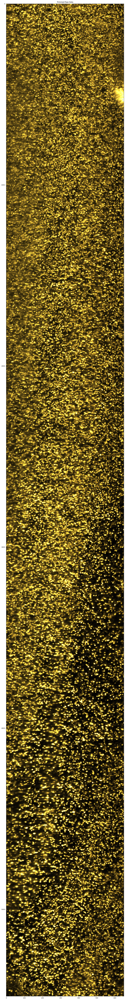

<Figure size 10000x10000 with 0 Axes>

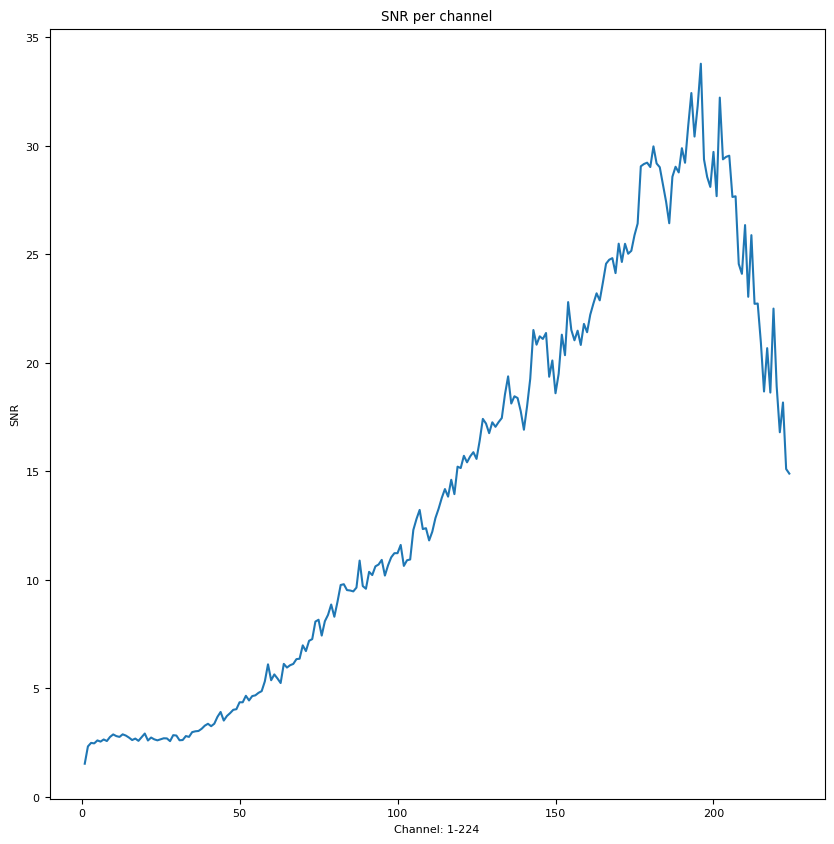

Good Bands:  [42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 138, 139, 220, 222, 223]
Bad Bands:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 133, 134, 135, 136, 137, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213

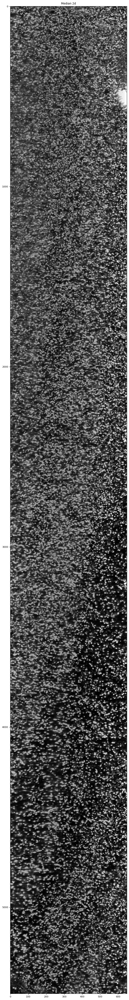

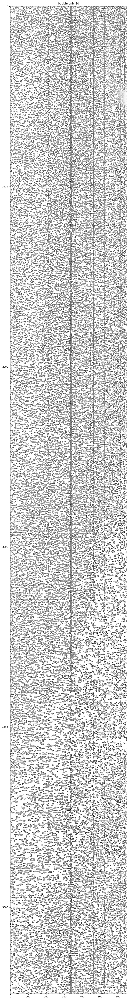

Median 2D shape: (5480, 650); Valid Median 2D shape: (5480, 650)
Global Median Radiance (from median_2d): 37.36420822143555
(100442, 2)
Found 46132 initial markers in median_2d
Markers stats: mean=695.29, max=46132, min=0, std=4626.18


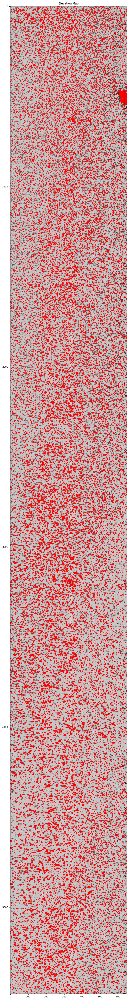

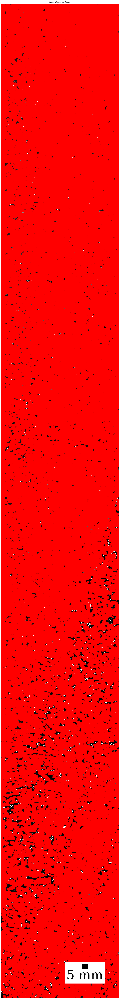

Top Depth = 26.07m
Crop Start Px = 1340
Px Per cm = 63.976377952755904
Minimum bubble size: 0.4886
Maximum bubble size: 4.2023
Bubble Count: 26734
Bubble 1:
  Area: 0.5131
  Centroid: (np.float64(1.0), np.float64(265.0))
  Orientation: 10.9 radians
  Elongation: 1.37
  Bounding Box: [0, 262, 4, 268]
Bubble 2:
  Area: 0.5131
  Centroid: (np.float64(1.0), np.float64(286.0))
  Orientation: 6.2 radians
  Elongation: 1.19
  Bounding Box: [0, 283, 5, 289]
Bubble 3:
  Area: 0.6108
  Centroid: (np.float64(2.0), np.float64(322.0))
  Orientation: 175.67 radians
  Elongation: 1.34
  Bounding Box: [0, 320, 5, 326]
Bubble 4:
  Area: 0.6841
  Centroid: (np.float64(2.0), np.float64(357.0))
  Orientation: 67.08 radians
  Elongation: 1.26
  Bounding Box: [0, 354, 6, 360]
Bubble 5:
  Area: 0.733
  Centroid: (np.float64(2.0), np.float64(471.0))
  Orientation: 176.03 radians
  Elongation: 1.66
  Bounding Box: [0, 468, 5, 476]
Bubble 6:
  Area: 0.5131
  Centroid: (np.float64(1.0), np.float64(502.0))
  Orie

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



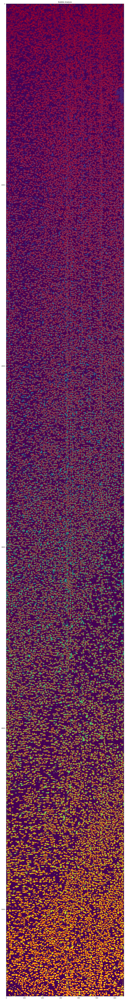

crop_start_px: 1340
crop_end_px: 6820
crop_end_px: 6820
original_start_px: 2470
pixels_per_cm: 63.976377952755904
top_depth_m: 26.07


In [6]:
trimmedData = processice.trim(data_nparr, w_ref, d_ref, px_dims, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
filtered_img, wvls, fwhm = processice.remove_bands(correctedData, trimmedData[1], wvls, fwhm, Debug=True, outputPath=outputPath, save=True)
print(f"\n--------------------------------------------   Bubbles   --------------------------------------------------------------------")
bubbles_only, bubble_masks, bubble_only_2d, bubble_channel_map = processbubbles.get_bubbles(filtered_img, fwhm, clean=False, debug=Debug)
#previewed_img = processice.previewImg(bubbles_only, "Bubbles Only")
print(f"\n-----------------------------------------------------------------------------------------------------------------------------")
df_map = pd.DataFrame([
    {"Bubble_ID": b_id, "Bands": bands, "Num_Bands": len(bands)}
    for b_id, bands in bubble_channel_map.items()
])
print(df_map)
# Output df

print(f"arr: type={type(filtered_img).__name__}, shape={getattr(filtered_img,'shape',None)}, ndim={getattr(filtered_img,'ndim',None)}, dtype={getattr(filtered_img,'dtype',None)}")


segmented_img, x_coords, y_coords = processbubbles.rad_watershed(filtered_img, bubble_only_2d)
watershed_boundaries, watershed_boundary_pixels = processbubbles.getBoundaries(segmented_img, x_coords, y_coords, filtered_img, Save=True, savepath=outputPath)

analyzed_bubbles, bubble_df, bubble_area_ratio = processbubbles.analyze_bubbles(segmented_img, dataSize[0], pixels_per_cm, top_depth, min_size=20, Debug=Debug, Save=True, savepath=outputPath)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Bubble Area Ratio: {bubble_area_ratio}%\n")
stats_df = processbubbles.get_stats(bubble_df, pixels_per_cm)

DSName = outputPath.parent.name
filename = f"{DSName}_bubbleData.csv"
bubble_df.to_csv(f"{outputPath}/{filename}", index=False)
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Output File: {filename}\n- {DSName}: CSV File of all detected bubbles and their properties\n")

df_bubbles_per_cm = processbubbles.process_bubbles_per_cm(filtered_img, analyzed_bubbles, segment_boundaries, dataSize[0], dataSize[1], 2470, pixels_per_cm, top_depth)

# # Save to CSV
# DSName = outputPath.parent.name
# filename = f"{DSName}bubbles_per_cm.csv"
# df_bubbles_per_cm.to_csv(f"{outputPath}/{filename}", index=False)
# readme_path = outputPath / "README.md"
# with readme_path.open("a") as f:
#     f.write(f"\n###  Output File: {filename}\n- {DSName}: CSV File of Bubble stats per cm\n")

# DSName = outputPath.parent.name
# filename = f"{DSName}_bubble_stats.csv"
# stats_df.to_csv(f"{outputPath}/{filename}", index=False)
# readme_path = outputPath / "README.md"
# with readme_path.open("a") as f:
#     f.write(f"\n###  Output File: {filename}\n- {DSName}: CSV File of Bubble stats across whole core section\n")

In [7]:
bubbles1 = f"{outputPath}/bubbles_per_cm.csv"

bubbles1_df = pd.read_csv(bubbles1)
bubbles1_df['Depth_cm'] = bubbles1_df['Depth_cm'] / 100

plt.figure(figsize=(5, 10))
ax = plt.gca()

# ---- bottom axis (blue) ----
ax.plot(bubbles1_df["Bubble_Count"], bubbles1_df["Depth_cm"], marker='o', alpha=0.7, color="C0", label="Transmissive")
ax.set_xlabel("Bubbles per cm²")
# ax.tick_params(axis="x")

# # ---- top axis (orange) ----
# ax.plot(bubbles2_df["Bubble_Count"], bubbles2_df["Depth_cm"], marker='x', alpha=0.7, color="C1", label="Reflective")

# ---- shared y-axis and styling ----
ax.set_ylabel("Depth (m)", fontweight="bold")
ax.set_title("ALHIC2302-29")
ax.invert_yaxis()
ax.grid(True)
ax.legend(loc="best", markerscale=2, fontsize=10)
plt.tight_layout()

plt.savefig(f"{outputPath}/Bubble_CountComparisonPlot.png", dpi=300, bbox_inches='tight')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29/2026-03-23_135520/bubbles_per_cm.csv'

In [ ]:
from bubbles import bubbles_count_module as count_bubbles
from bubbles import bubble_analysis_module as analyze

def process_bubbles_per_cm(
    cropped_image: np.ndarray,
    bubble_properties: list[dict],
    segment_boundaries: list[tuple[int, int]],
    crop_start_px: int,
    crop_end_px: int,
    original_start_px: int,
    pixels_per_cm: float,
    top_depth: float,
    slice_thickness_cm: float = 3.0
) -> pd.DataFrame:
    """
    Processes bubble segmentation and counting for a cropped ice core image.

    Args:
    - cropped_image (np.ndarray): Cropped ice core image.
    - segment_boundaries (list of tuples): Original (start_px, end_px) per cm.
    - crop_start_px (int): Start pixel of the cropped image.
    - crop_end_px (int): End pixel of the cropped image.
    - original_start_px (int): Original ice start pixel before cropping.
    - pixels_per_cm (float): Conversion factor from pixels to cm.
    - top_depth (float): Core section depth for table.

    Returns:
    - pd.DataFrame: DataFrame with depth in cm and bubble counts.
    """
    crop_start_px = int(crop_start_px)
    crop_end_px = int(crop_end_px)
    
    # Adjust segment boundaries for the cropped image
    adjusted_segments, new_pixels_per_cm = adjust_boundaries_for_crop(segment_boundaries, crop_start_px, crop_end_px, 
                                                                     original_start_px, pixels_per_cm)

    # Count and normalize bubble data in each adjusted segment
    total_counts, normalized_counts, BND, ice_to_bubble_ratios, avg_bubble_sizes, avg_elongations, avg_eccentricities, avg_orientations, std_sizes, std_elongations, std_eccentricities, std_orientations, median_sizes, median_elongations, median_eccentricities, median_orientations, trimmed_mean_sizes, trimmed_mean_elongations, trimmed_mean_eccentricities, trimmed_mean_orientations = count_bubbles_in_segments(
        cropped_image, bubble_properties, adjusted_segments, new_pixels_per_cm, slice_thickness_cm
    )

    # Generate the output DataFrame
    bubble_segments_df = generate_bubble_dataframe(
        total_counts, normalized_counts, ice_to_bubble_ratios, avg_bubble_sizes,
        BND, avg_elongations, avg_eccentricities, avg_orientations, std_sizes, std_elongations, std_eccentricities, std_orientations, median_sizes, median_elongations, median_eccentricities, median_orientations, trimmed_mean_sizes, trimmed_mean_elongations, trimmed_mean_eccentricities, trimmed_mean_orientations, adjusted_segments, top_depth
    )
    return bubble_segments_df

def adjust_boundaries_for_crop(segment_boundaries, crop_start_px, crop_end_px, original_start_px, pixels_per_cm):
    """
    Adjusts the segment boundaries to match a cropped image.

    Args:
    - segment_boundaries (list of tuples): Original (start_px, end_px) per cm.
    - crop_start_px (int): New start pixel after cropping.
    - crop_end_px (int): New end pixel after cropping.
    - original_start_px (int): Original ice start pixel before cropping.
    - pixels_per_cm (float): Conversion factor from pixels to cm.

    Returns:
    - adjusted_segments (list of tuples): Updated (start_px, end_px) per cm.
    - new_pixels_per_cm (float): Adjusted conversion factor.
    """

    adjusted_segments = []
    for start, end in segment_boundaries:
        new_start = start - crop_start_px
        new_end = end - crop_start_px

        # Keep only fully visible segments
        if new_start >= 0 and new_end <= (crop_end_px - crop_start_px):
            adjusted_segments.append((new_start, new_end))

    # Update pixels_per_cm for the cropped image
    new_ice_height_px = crop_end_px - crop_start_px
    new_pixels_per_cm = 63.976377952755904

    return adjusted_segments, new_pixels_per_cm

def count_bubbles_in_segments(
    cropped_image: np.ndarray,
    bubble_properties: list[dict],
    adjusted_segments: list[tuple[int, int]],
    pixels_per_cm: float,
    slice_thickness_cm: float = 3.0
) -> tuple[
    list[int], list[float], list[float], list[float],
    list[float], list[float], list[float], list[float]
]:
    """
    Computes bubble counts and morphology for the centermost 1 cm x 1 cm area of each segment.

    Returns:
    - total_counts: Total bubbles in central tile
    - normalized_counts: Bubbles per cm²
    - BND: Bubble number density (bubbles/cm³)
    - ice_to_bubble_ratios: % of tile that is bubble pixels
    - avg_bubble_sizes, avg_elongations, avg_eccentricities, avg_orientations
    """
    total_counts, normalized_counts, density, BND = [], [], [], []
    ice_to_bubble_ratios, avg_bubble_sizes = [], []
    avg_elongations, avg_eccentricities, avg_orientations = [], [], []
    std_sizes, std_elongations, std_eccentricities, std_orientations = [], [], [], []
    median_sizes, median_elongations, median_eccentricities, median_orientations = [], [], [], []
    trimmed_mean_sizes, trimmed_mean_elongations, trimmed_mean_eccentricities, trimmed_mean_orientations = [], [], [], []

    width_px = cropped_image.shape[1]
    tile_px = int(round(pixels_per_cm))  # 1 cm in pixels
    tile_area_cm2 = 1.0  # 1 x 1 cm

    for i in range(len(adjusted_segments)):
        segment = adjusted_segments[i]
        
        group_start = segment[0]
        group_end = segment[1]
        group_height_px = group_end - group_start
        if group_height_px <= 0:
            print("group_height_px <= 0")
            # Shouldn't happen
            total_counts.append(0)
            normalized_counts.append(0.0)
            density.append(0.0)
            BND.append(0.0)
            ice_to_bubble_ratios.append(0.0)
            avg_bubble_sizes.append(0.0)
            avg_elongations.append(0.0)
            avg_eccentricities.append(0.0)
            avg_orientations.append(0.0)
            continue


        # Center of the cm block
        x_center = width_px // 2
        y_center = group_start + group_height_px // 2

        # Compute cm tile at center
        x_start = x_center - tile_px // 2
        x_end = x_start + tile_px
        if x_start < 0:
            x_end -= x_start  # shift right
            x_start = 0
        if x_end > width_px:
            shift = x_end - width_px
            x_start = max(0, x_start - shift)
            x_end = width_px

        y_start = y_center - tile_px // 2
        y_end = y_start + tile_px
        if y_start < group_start:
            # shift down to fit inside block
            y_end += (group_start - y_start)
            y_start = group_start
        if y_end > group_end:
            shift = y_end - group_end
            y_start = max(group_start, y_start - shift)
            y_end = group_end

        # In rare rounding cases, ensure full tile size vertically
        # if (y_end - y_start) < tile_px or (x_end - x_start) < tile_px:
        #     # No partial tiles for consistency
        #     print("partial tile")
        #     continue

        # Bubbles w/ centroids in the 5x5 tile
        tile_bubbles = [
            b for b in bubble_properties
            if (x_start <= b["x"] < x_end) and (y_start <= b["y"] < y_end)
        ]
        count_tile = len(tile_bubbles)
        # print(f"count_tile for group{group}: {count_tile}")
        total_counts.append(count_tile)

        # Normalized to cm² (same as count cuz tile area is fixed)
        normalized_counts.append(count_tile)

        # Density (bubbles/cm²) and BND (bubbles/cm³)
        dens_cm2 = count_tile / tile_area_cm2
        density.append(dens_cm2)
        BND.append(dens_cm2 / slice_thickness_cm if slice_thickness_cm > 0 else 0.0)

        # Morphology
        if count_tile > 0:
            areas_px2 = [b["area"] for b in tile_bubbles]
            total_bubble_area_px2 = float(sum(areas_px2))

            
            areas_px2 = np.array([b["area"] for b in tile_bubbles])
            elongations = np.array([b["elongation"] for b in tile_bubbles])
            eccentricities = np.array([b["eccentricity"] for b in tile_bubbles])
            orientations = np.array([b["orientation"] for b in tile_bubbles])
            
            def mean_within_std(values: np.ndarray) -> float:
                """Return mean with values outside 1 std from mean removed."""
                mean = np.mean(values)
                std = np.std(values)
                mask = (values >= mean - std) & (values <= mean + std)
                filtered = values[mask]
                return float(np.mean(filtered)) if len(filtered) > 0 else float("nan")
            
            # Means
            mean_size = float(np.mean(areas_px2))
            mean_elongation = float(np.mean(elongations))
            mean_eccentricity = float(np.mean(eccentricities))
            mean_orientation = float(np.mean(orientations))
            
            # Standard deviations
            std_size = float(np.std(areas_px2, ddof=1))
            std_elongation = float(np.std(elongations, ddof=1))
            std_eccentricity = float(np.std(eccentricities, ddof=1))
            std_orientation = float(np.std(orientations, ddof=1))
            
            # Medians
            median_size = float(np.median(areas_px2))
            median_elongation = float(np.median(elongations))
            median_eccentricity = float(np.median(eccentricities))
            median_orientation = float(np.median(orientations))
            
            # Trimmed means (excluding points outside ±1 std)
            trimmed_mean_size = mean_within_std(areas_px2)
            trimmed_mean_elongation = mean_within_std(elongations)
            trimmed_mean_eccentricity = mean_within_std(eccentricities)
            trimmed_mean_orientation = mean_within_std(orientations)

            
        else:
            total_bubble_area_px2 = 0.0
            median_size = median_elongation = median_eccentricity = median_orientation = 0.0
            mean_size = mean_elongation = mean_eccentricity = mean_orientation = 0.0
            std_size = std_elongation = std_eccentricity = std_orientation = 0.0
            trimmed_mean_size = trimmed_mean_elongation = trimmed_mean_eccentricity = trimmed_mean_orientation = 0.0

        # % of 5x5 tile area that’s bubble pixels (pixel-based ratio)
        tile_area_px = tile_px * tile_px
        ice_to_bubble_ratio = (
            round((total_bubble_area_px2 / tile_area_px) * 100.0, 2)
            if tile_area_px > 0 else 0.0
        )

        ice_to_bubble_ratios.append(ice_to_bubble_ratio)
        avg_bubble_sizes.append(mean_size)
        avg_elongations.append(mean_elongation)
        avg_eccentricities.append(mean_eccentricity)
        avg_orientations.append(mean_orientation)

        std_sizes.append(std_size)
        std_elongations.append(std_elongation)
        std_eccentricities.append(std_eccentricity)
        std_orientations.append(std_orientation)

        median_sizes.append(median_size)
        median_elongations.append(median_elongation)
        median_eccentricities.append(median_eccentricity)
        median_orientations.append(median_orientation)

        trimmed_mean_sizes.append(trimmed_mean_size)
        trimmed_mean_elongations.append(trimmed_mean_elongation)
        trimmed_mean_eccentricities.append(trimmed_mean_eccentricity)
        trimmed_mean_orientations.append(trimmed_mean_orientation)

    #print("Depth_cm length: ", len(depths_cm))
    # print("Bubble_Count length: ", len(total_counts))
    # print("Avg_Bubble_Size length: ", len(avg_bubble_sizes))
    # print("Bubble_Area_Ratio length: ", len(ice_to_bubble_ratios))
    # print("BND length: ", len(BND))
    # print("Avg_Elongation length: ", len(avg_elongations))
    # print("Avg_Eccentricity length: ", len(avg_eccentricities))
    # print("Avg_Orientation length: ", len(avg_orientations))

    return (
        total_counts,          # bubbles in central 1 cm tile
        normalized_counts,     # bubbles per cm²
        BND,                   # bubbles/cm³
        ice_to_bubble_ratios,  # % tile area that's bubbles
        avg_bubble_sizes,
        avg_elongations,
        avg_eccentricities,
        avg_orientations,
        std_sizes,
        std_elongations,
        std_eccentricities,
        std_orientations,
        median_sizes,
        median_elongations,
        median_eccentricities,
        median_orientations,
        trimmed_mean_sizes,
        trimmed_mean_elongations,
        trimmed_mean_eccentricities,
        trimmed_mean_orientations
    )
 



def generate_bubble_dataframe(
    total_counts: list[int],
    normalized_counts: list[int],
    ice_to_bubble_ratios: list[float],
    avg_bubble_sizes: list[float],
    BND: list[float],
    avg_elongations: list[float],
    avg_eccentricities: list[float],
    avg_orientations: list[float],
    std_sizes: list[float], 
    std_elongations: list[float], 
    std_eccentricities: list[float], 
    std_orientations: list[float], 
    median_sizes: list[float], 
    median_elongations: list[float],
    median_eccentricities: list[float],
    median_orientations: list[float],
    trimmed_mean_sizes: list[float],
    trimmed_mean_elongations: list[float],
    trimmed_mean_eccentricities: list[float],
    trimmed_mean_orientations: list[float],
    adjusted_segments: list[tuple[int, int]],
    top_depth: float
) -> pd.DataFrame:
    """
    Creates a DataFrame with depth-resolved bubble morphology and density metrics.

    Args:
    - total_counts: Number of bubbles in each segment.
    - normalized_counts: Average number of bubbles per cm^2, per cm of depth
    - ice_to_bubble_ratios: Percent area of each segment occupied by bubbles.
    - avg_bubble_sizes: Average bubble size (in px) in each segment.
    - BND: Bubble Number Density per cm^3 for each segment.
    - avg_elongations: Average elongation per segment.
    - avg_eccentricities: Average eccentricity per segment.
    - avg_orientations: Average orientation per segment.
    - adjusted_segments: Pixel ranges for each 1 cm segment.
    - top_depth: Depth (in meters) at top of the core section.

    Returns:
    - pd.DataFrame with all metrics per 1 cm depth increment.
    """
    start_cm = int(top_depth * 100)
    depths_cm = np.arange(start_cm, start_cm + (len(adjusted_segments)))

    # print("Depth_cm length: ", len(depths_cm))
    # print("Depth_cm: ", depths_cm)
    # print("Bubble_Count length: ", len(total_counts))
    # print("Avg_Bubble_Size length: ", len(avg_bubble_sizes))
    # print("Bubble_Area_Ratio length: ", len(ice_to_bubble_ratios))
    # print("BND length: ", len(BND))
    # print("Avg_Elongation length: ", len(avg_elongations))
    # print("Avg_Eccentricity length: ", len(avg_eccentricities))
    # print("Avg_Orientation length: ", len(avg_orientations))

    df = pd.DataFrame({
        "Depth_cm": depths_cm,
        "Bubble_Count": total_counts,
        "Normalized_Count": normalized_counts,
        "Bubble_Number_Density": BND,
        "Avg_Bubble_Size": avg_bubble_sizes,
        "Bubble_Area_Ratio": ice_to_bubble_ratios,
        "Avg_Elongation": avg_elongations,
        "Avg_Eccentricity": avg_eccentricities,
        "Avg_Orientation": avg_orientations,
        "STD_Bubble_Size": std_sizes,
        "STD_Elongation": std_elongations,
        "STD_Eccentricity": std_eccentricities,
        "STD_Orientation": std_orientations,
        "Median_Bubble_Size": median_sizes,
        "Median_Elongation": median_elongations,
        "Median_Eccentricity": median_eccentricities,
        "Median_Orientation": median_orientations,
        "Trimmed_Mean_Bubble_Size": trimmed_mean_sizes,
        "Trimmed_Mean_Elongation": trimmed_mean_elongations,
        "Trimmed_Mean_Eccentricity": trimmed_mean_eccentricities,
        "Trimmed_Mean_Orientation": trimmed_mean_orientations
    })

    return df

In [ ]:
df_bubbles_per_cm = process_bubbles_per_cm(filtered_img, analyzed_bubbles, segment_boundaries, dataSize[0], dataSize[1], 2470, pixels_per_cm, top_depth)

In [ ]:
df_bubbles_per_cm.to_csv(f"{outputPath}/bubbles_per_cm.csv", index=False)

In [ ]:
print(df_bubbles_per_cm)

In [ ]:
print(stats_df)

In [ ]:
processbubbles.graph_bubble_stats(df_bubbles_per_cm, save=True, savepath=outputPath)

In [ ]:
previewed_img = processice.previewImg(bubbles_only, "Bubbles Only")
# sums_img, full_img_sums = processSums.channel_sums(bubbles_only, pixels_per_cm, top_depth, Debug)
# combined_df, per_section = processSums.sum_comparison(bubbles_only, pixels_per_cm, top_depth, Debug)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 20))
plt.scatter(df_bubbles_per_cm['Median_Bubble_Size'], df_bubbles_per_cm['Depth_cm'], color='tab:blue', marker='o')
plt.gca().invert_yaxis()
plt.xlabel('Median Size')
plt.ylabel('Depth (cm)')
plt.grid(True)
plt.show

In [ ]:
# from pathlib import Path
# from typing import Optional, Dict
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.decomposition import PCA
# from sklearn.preprocessing import StandardScaler

# def plot_stats_by_depth(df: pd.DataFrame,
#                         save: bool = False,
#                         save_path: Optional[Path | str] = None,
#                         show: bool = True,
#                         invert_depth_axis: bool = True,
#                         shade_gaps: bool = False,
#                         gap_threshold: float = 2.0,
#                         # --- PCA options ---
#                         do_pca: bool = False,
#                         pca_n_components: int = 2,
#                         standardize: bool = True) -> Dict[str, Optional[Path]]:
#     """
#     Create a single figure with three subplots: Sums, Means, and Medians vs Depth.
#     Optionally shade depth gaps larger than `gap_threshold` cm.

#     If do_pca=True:
#       - Runs PCA on ['Sums','Means','Medians'] (standardized if standardize=True).
#       - Plots a PC1 vs PC2 scatter colored by Depth.
#       - Prints explained variance ratios to stdout.

#     Args:
#         df: DataFrame with columns ['Depth_cm','Sums','Means','Medians'].
#         save: If True, writes PNGs to save_path.
#         save_path: Directory to save plots (created if needed).
#         show: If True, displays plots interactively.
#         invert_depth_axis: If True, puts greater depth lower on the figure.
#         shade_gaps: If True, shade intervals where depth jumps exceed `gap_threshold`.
#         gap_threshold: Minimum gap size (cm) that triggers shading.
#         do_pca: Whether to run/plot PCA.
#         pca_n_components: Target number of PCA components (<= 3 here).
#         standardize: Standardize features before PCA (recommended).

#     Returns:
#         Dict with keys:
#             'stats_by_depth' -> Path (or None)
#             'pca_scatter'    -> Path (or None; only if do_pca)
#     """
#     required = {"Depth_cm", "Sums", "Medians", "Means"}
#     missing = required.difference(df.columns)
#     if missing:
#         raise ValueError(f"DataFrame missing columns: {sorted(missing)}")

#     # Clean & sort
#     dfx = df.copy()
#     dfx["Depth_cm"] = pd.to_numeric(dfx["Depth_cm"], errors="coerce")
#     dfx["Sums"] = pd.to_numeric(dfx["Sums"], errors="coerce")
#     dfx["Medians"] = pd.to_numeric(dfx["Medians"], errors="coerce")
#     dfx["Means"] = pd.to_numeric(dfx["Means"], errors="coerce")
#     dfx = dfx.dropna(subset=["Depth_cm", "Sums", "Medians", "Means"]).sort_values("Depth_cm")

#     if dfx.empty:
#         raise ValueError("No valid rows after cleaning input DataFrame.")

#     if save:
#         save_dir = Path(save_path) if save_path is not None else Path(".")
#         save_dir.mkdir(parents=True, exist_ok=True)
#     else:
#         save_dir = None

#     # ----- Stats-by-depth plot -----
#     fig, axes = plt.subplots(1, 3, figsize=(12, 10), sharey=True)

#     stats = [("Sums", dfx["Sums"]), ("Medians", dfx["Medians"]), ("Means", dfx["Means"])]
#     for ax, (label, data) in zip(axes, stats):
#         ax.scatter(data, dfx["Depth_cm"], s=1.5)
#         ax.set_xlabel(label)
#         ax.grid(axis="y", linestyle="--", alpha=0.4)

#         if shade_gaps:
#             depths = dfx["Depth_cm"].to_numpy()
#             gaps = np.where(np.diff(depths) > gap_threshold)[0]
#             for g in gaps:
#                 y1, y2 = depths[g], depths[g + 1]
#                 ax.axhspan(y1, y2, color="gray", alpha=0.15)

#         if invert_depth_axis:
#             ax.invert_yaxis()
#         if ax is axes[0]:
#             ax.set_ylabel("Depth (cm)")

#     fig.suptitle("Bubble Only Pixel Intensity", fontsize=14)
#     fig.tight_layout()

#     out_stats = None
#     if save:
#         out_stats = save_dir / (f"{DataID}bubbleOnlyIntensity_shaded.png" if shade_gaps else f"{DataID}bubbleOnlyIntensity.png")
#         fig.savefig(out_stats, dpi=300, bbox_inches="tight")
#     if show:
#         plt.show()
#     else:
#         plt.close(fig)

#     # ----- Optional PCA -----
#     out_pca = None
#     if do_pca:
#         features = ["Sums", "Means", "Medians"]
#         X = dfx[features].to_numpy()

#         # n_components must be <= min(n_samples, n_features)
#         max_comps = min(pca_n_components, X.shape[0], X.shape[1])
#         if max_comps < 1:
#             raise ValueError("Not enough data to run PCA (need at least 1 component).")

#         X_proc = StandardScaler().fit_transform(X) if standardize else X
#         pca = PCA(n_components=max_comps)
#         pcs = pca.fit_transform(X_proc)

#         # Report variance explained
#         evr = pca.explained_variance_ratio_
#         print(f"PCA explained variance ratio (first {max_comps}): {np.round(evr, 4)}")

#         # If at least 2 components, make a scatter; otherwise, plot PC1 vs depth
#         if max_comps >= 2:
#             plt.figure(figsize=(6, 5))
#             sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=dfx["Depth_cm"], s=10, cmap="viridis")
#             plt.colorbar(sc, label="Depth (cm)")
#             plt.xlabel("PC1")
#             plt.ylabel("PC2")
#             plt.title("PCA of Sums, Means, Medians")
#             plt.grid(alpha=0.3)
#         else:
#             # 1D PCA: show PC1 vs depth
#             plt.figure(figsize=(6, 5))
#             plt.scatter(pcs[:, 0], dfx["Depth_cm"], s=10)
#             plt.gca().invert_yaxis()  # depth convention
#             plt.xlabel("PC1")
#             plt.ylabel("Depth (cm)")
#             plt.title("PCA (1 component) of Sums, Means, Medians")
#             plt.grid(alpha=0.3)

#         if save:
#             out_pca = Path(outputPath) / "pca_scatter.png"
#             #plt.savefig(out_pca, dpi=300, bbox_inches="tight")

#         if show:
#             plt.show()
#         else:
#             plt.close()

#     return {
#         "stats_by_depth": out_stats,
#         "pca_scatter": out_pca
#     }

In [ ]:
# results = plot_stats_by_depth(
#     full_img_sums,
#     save=False,
#     save_path='/data/icecores/Output/Figures',
#     show=True,
#     invert_depth_axis=True,
#     shade_gaps=False,
#     gap_threshold=2.0
# )

In [ ]:
# from scipy.signal import find_peaks

# signal = full_img_sums['Sums']

# fig, ax = plt.subplots(figsize=(5, 15))
# depth = full_img_sums['Depth_cm']
# ax.scatter(signal, depth, label='Cumulative Pixel Intensity', s=1.5)  # x='Sums', y='Depth'
# plt.show()

# # Find peaks
# peaks, _ = find_peaks(signal, prominence=0.2, distance=50, width=10)
# # Find valleys
# valleys, _ = find_peaks(-signal, prominence=0.2, distance=50, width=20)

# plt.figure(figsize=(5, 15))
# plt.plot(signal, depth, label="Px Intensity", color="gray")

# # Highlight peaks
# plt.plot(signal.iloc[peaks], depth.iloc[peaks], "r^", label="Peaks")

# # Highlight valleys
# plt.plot(signal.iloc[valleys], depth.iloc[valleys], "bv", label="Valleys")

# plt.gca().invert_yaxis()  # optional for depth-based plots
# plt.ylabel("Depth (cm)")
# plt.xlabel("Pixel Intensity")
# plt.title("Pixel Intensity: Peaks and Valleys")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/HSIUM-104_CumulativeIntensityPeaksValleys.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

# print("Peaks: ", peaks)
# print("Valleys: ", valleys)

In [ ]:
# if bubbles_only.ndim != 3:
#         raise ValueError("Expected image with shape (height, width, channels)")

# H, W, C = bubbles_only.shape
# # Use float64 for stable reductions
# imgf = bubbles_only.astype(np.float64, copy=False)

# # Row-wise reductions over width and channels -> shape (H,)
# row_sums  = np.sum(imgf, axis=1)        # total per row

# heights =[1377, 1860, 1925, 2053, 2521, 2808, 2926, 3063, 3128, 3193, 3414, 3523, 3596, 3952,
#  4010, 4077, 4230, 4311, 4688, 4761, 4838, 4889, 4946, 5010, 5133, 5213, 5360]          # example indices, adjust as needed
# spectra = row_sums[heights, :]      # shape: (3, C)

# # --- Plot spectra for each height ---
# plt.figure(figsize=(8, 8))
# for i, h in enumerate(heights):
#     h=h-2
#     plt.plot(np.arange(imgf.shape[2]), spectra[i], label=f"Height {h}")

# plt.xlabel("Spectral Channel")
# plt.ylabel("Cumulative Intensity (over width)")
# plt.title("Spectral Profiles at Selected Heights")
# plt.legend()
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/HSIUM-103_BubblesOnlyCumulativeIntensityPeakProfiles.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# if bubbles_only.ndim != 3:
#         raise ValueError("Expected image with shape (height, width, channels)")

# H, W, C = bubbles_only.shape
# # Use float64 for stable reductions
# imgf = bubbles_only.astype(np.float64, copy=False)

# # Row-wise reductions over width and channels -> shape (H,)
# row_sums  = np.sum(imgf, axis=1)        # total per row

# heights =[314, 688, 907, 980, 1065, 3167, 3248, 3360, 3428, 3729, 4293, 5425]    # example indices, adjust as needed
# spectra = row_sums[heights, :]      # shape: (3, C)

# # --- Plot spectra for each height ---
# plt.figure(figsize=(8, 8))
# for i, h in enumerate(heights):
#     h=h-2
#     plt.plot(np.arange(imgf.shape[2]), spectra[i], label=f"Height {h}")

# plt.xlabel("Spectral Channel")
# plt.ylabel("Cumulative Intensity (over width)")
# plt.title("Spectral Profiles at Selected Heights")
# plt.legend()
# plt.tight_layout()
# outputPath = '/data/icecores/Output/Figures'
# out_path = f"{outputPath}/HSIUM-103_BubblesOnlyCumulativeIntensityValleyProfiles.png"
# # plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()